Class 1 shape: (1000, 2)
Class 2 shape: (1000, 2)
Total samples: 2000


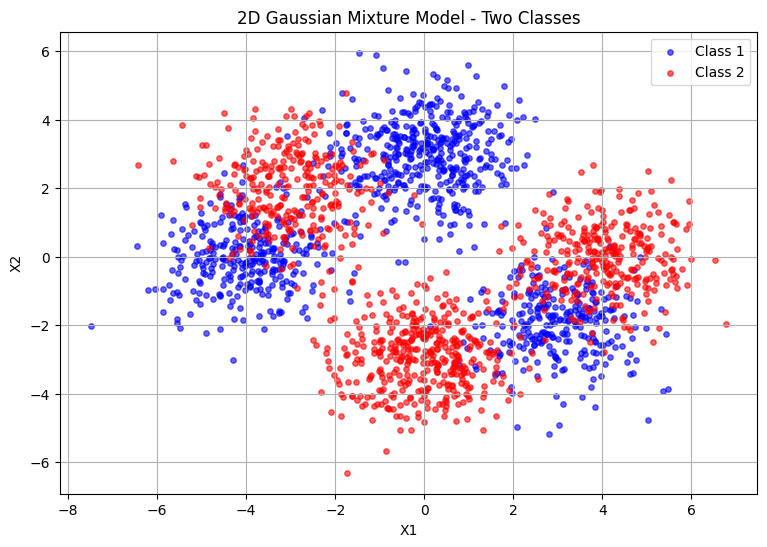

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Number of samples per class
N = 1000

# Number of Gaussian components per class
K = 3

# Mixture weights (must sum to 1)
weights = [0.3, 0.4, 0.3]

# Mean values for Class 1
means_1 = [
    [-4, 0],
    [0, 3],
    [3, -2]
]

# Mean values for Class 2
means_2 = [
    [4, 0],
    [0, -3],
    [-3, 2]
]

# Covariance matrices (spherical covariance for now)
covariances = [
    [[1, 0], [0, 1]],
    [[1, 0], [0, 1]],
    [[1, 0], [0, 1]]
]

# Function to generate Gaussian mixture data
def generate_data(N, means, weights, covariances):
    data = []
    component_labels = []

    for _ in range(N):
        # Randomly select a Gaussian component
        component = np.random.choice(
            len(weights), p=weights
        )

        # Generate one 2D point
        point = np.random.multivariate_normal(
            means[component],
            covariances[component]
        )

        data.append(point)
        component_labels.append(component)

    return np.array(data), np.array(component_labels)


# Generate both classes
X1, components1 = generate_data(
    N, means_1, weights, covariances
)

X2, components2 = generate_data(
    N, means_2, weights, covariances
)

print("Class 1 shape:", X1.shape)
print("Class 2 shape:", X2.shape)
print("Total samples:", len(X1) + len(X2))


plt.figure(figsize=(9, 6))

plt.scatter(
    X1[:, 0], X1[:, 1],
    color="blue", label="Class 1",
    alpha=0.6, s=15
)

plt.scatter(
    X2[:, 0], X2[:, 1],
    color="red", label="Class 2",
    alpha=0.6, s=15
)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("2D Gaussian Mixture Model - Two Classes")
plt.legend()
plt.grid(True)
plt.show()

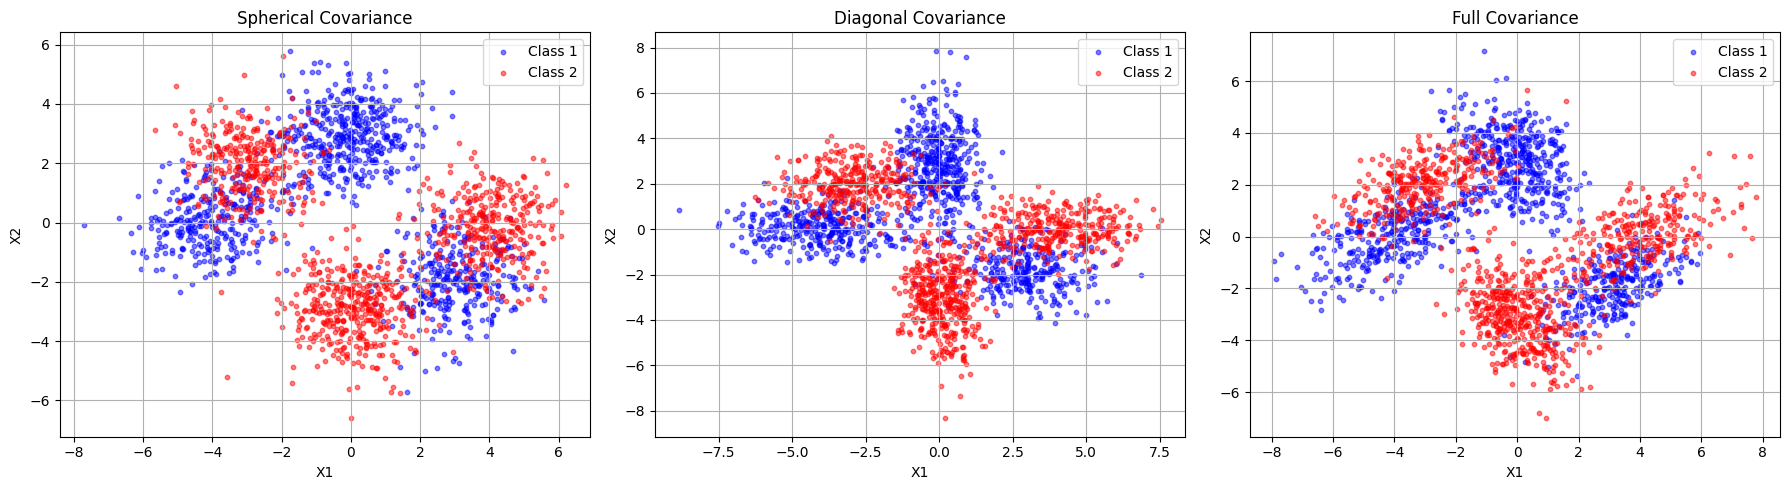

In [4]:

# Step 2: Compare three covariance types

cov_spherical = [
    [[1, 0], [0, 1]],
    [[1, 0], [0, 1]],
    [[1, 0], [0, 1]]
]

cov_diagonal = [
    [[2.0, 0], [0, 0.5]],
    [[0.5, 0], [0, 2.0]],
    [[1.5, 0], [0, 0.7]]
]

cov_full = [
    [[2.0, 0.8], [0.8, 1.0]],
    [[1.0, -0.6], [-0.6, 1.5]],
    [[1.5, 0.7], [0.7, 1.0]]
]

covariance_types = [
    ("Spherical", cov_spherical),
    ("Diagonal", cov_diagonal),
    ("Full", cov_full)
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, covs) in zip(axes, covariance_types):

    # Generate data for both classes
    X1_exp, _ = generate_data(N, means_1, weights, covs)
    X2_exp, _ = generate_data(N, means_2, weights, covs)

    ax.scatter(
        X1_exp[:, 0], X1_exp[:, 1],
        color="blue", s=10, alpha=0.5,
        label="Class 1"
    )

    ax.scatter(
        X2_exp[:, 0], X2_exp[:, 1],
        color="red", s=10, alpha=0.5,
        label="Class 2"
    )

    ax.set_title(name + " Covariance")
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()


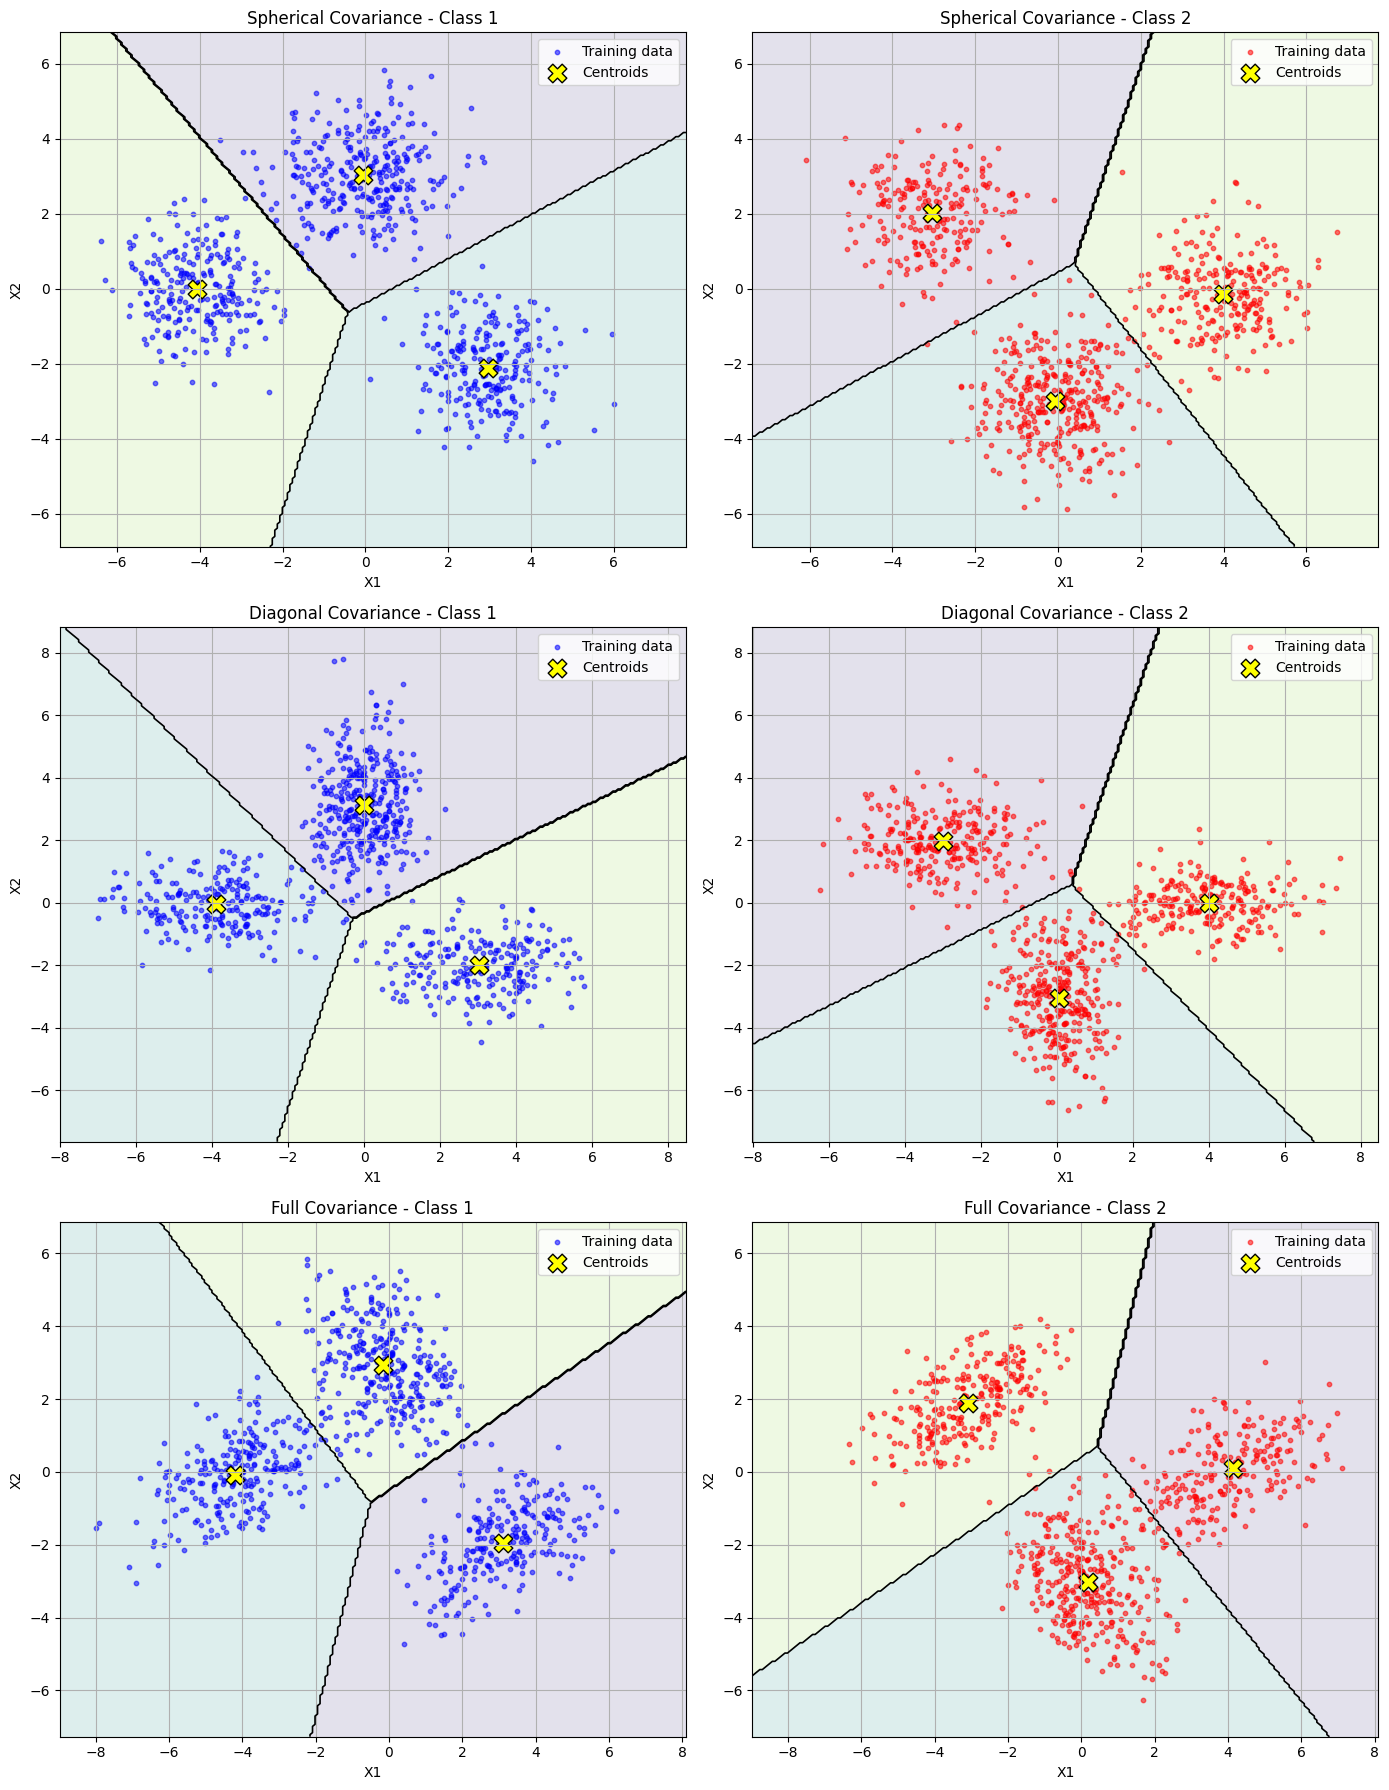

In [5]:

from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt

# Covariance experiments
covariance_types = [
    ("Spherical", cov_spherical),
    ("Diagonal", cov_diagonal),
    ("Full", cov_full)
]

fig, axes = plt.subplots(3, 2, figsize=(14, 18))

for row, (cov_name, covs) in enumerate(covariance_types):

    # Generate data for both classes
    X1, _ = generate_data(N, means_1, weights, covs)
    X2, _ = generate_data(N, means_2, weights, covs)

    # Split each class separately: 80% training, 20% testing
    X1_train, X1_test = train_test_split(
        X1, test_size=0.2, random_state=42
    )

    X2_train, X2_test = train_test_split(
        X2, test_size=0.2, random_state=42
    )

    for col, (X_train, class_name, color) in enumerate([
        (X1_train, "Class 1", "blue"),
        (X2_train, "Class 2", "red")
    ]):

        # Fit K-means using training data only
        kmeans = KMeans(
            n_clusters=3,
            random_state=42,
            n_init=10
        )
        kmeans.fit(X_train)

        # Create a grid covering the plot
        x_min = min(X1_train[:, 0].min(),
                    X2_train[:, 0].min()) - 1
        x_max = max(X1_train[:, 0].max(),
                    X2_train[:, 0].max()) + 1
        y_min = min(X1_train[:, 1].min(),
                    X2_train[:, 1].min()) - 1
        y_max = max(X1_train[:, 1].max(),
                    X2_train[:, 1].max()) + 1

        xx, yy = np.meshgrid(
            np.linspace(x_min, x_max, 250),
            np.linspace(y_min, y_max, 250)
        )

        grid = np.c_[xx.ravel(), yy.ravel()]

        # Assign each grid point to its nearest centroid
        Z = kmeans.predict(grid).reshape(xx.shape)

        ax = axes[row, col]

        # Shade the three cluster regions
        ax.contourf(
            xx, yy, Z,
            levels=np.arange(-0.5, 3.5, 1),
            alpha=0.15
        )

        # Draw boundaries between clusters
        ax.contour(
            xx, yy, Z,
            levels=[0.5, 1.5],
            colors="black",
            linewidths=1.2
        )

        # Plot training data
        ax.scatter(
            X_train[:, 0], X_train[:, 1],
            c=color, s=10, alpha=0.55,
            label="Training data"
        )

        # Plot centroids
        ax.scatter(
            kmeans.cluster_centers_[:, 0],
            kmeans.cluster_centers_[:, 1],
            c="yellow", edgecolors="black",
            marker="X", s=180,
            label="Centroids"
        )

        ax.set_title(f"{cov_name} Covariance - {class_name}")
        ax.set_xlabel("X1")
        ax.set_ylabel("X2")
        ax.grid(True)
        ax.legend()

plt.tight_layout()
plt.show()



 Spherical Covariance
Accuracy: 84.5 %
Confusion matrix:
[[170  30]
 [ 32 168]]

 Diagonal Covariance
Accuracy: 88.5 %
Confusion matrix:
[[175  25]
 [ 21 179]]

 Full Covariance
Accuracy: 82.75 %
Confusion matrix:
[[159  41]
 [ 28 172]]


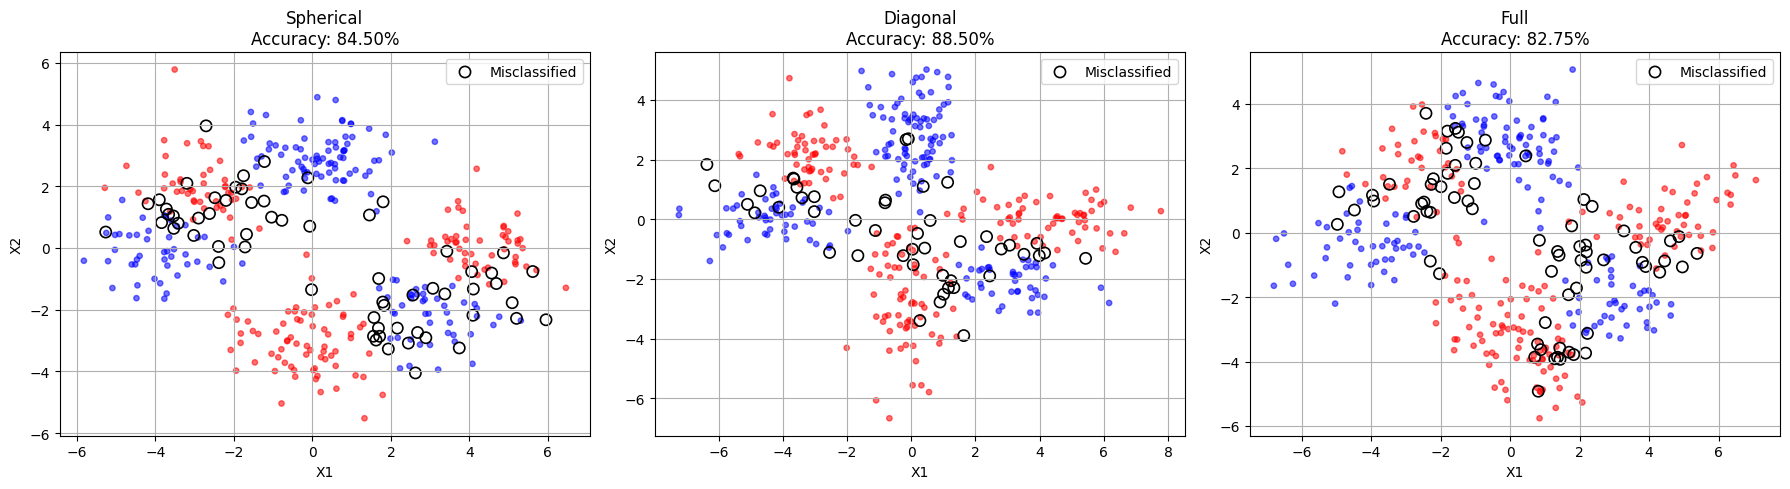

In [9]:

from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt

covariance_types = [
    ("Spherical", cov_spherical),
    ("Diagonal", cov_diagonal),
    ("Full", cov_full)
]

results = {}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (cov_name, covs) in zip(axes, covariance_types):

    # Generate data for both classes
    X1, _ = generate_data(N, means_1, weights, covs)
    X2, _ = generate_data(N, means_2, weights, covs)

    # Split into 80% training and 20% testing
    X1_train, X1_test = train_test_split(
        X1, test_size=0.2, random_state=42
    )
    X2_train, X2_test = train_test_split(
        X2, test_size=0.2, random_state=42
    )

    # Train separate K-means models
    km1 = KMeans(n_clusters=3, random_state=42, n_init=10)
    km2 = KMeans(n_clusters=3, random_state=42, n_init=10)

    km1.fit(X1_train)
    km2.fit(X2_train)

    # Combine the test data and true labels
    X_test = np.vstack((X1_test, X2_test))
    y_true = np.array(
        [0] * len(X1_test) + [1] * len(X2_test)
    )

    # Calculate squared distances to every centroid
    dist_class1 = np.sum(
        (X_test[:, None, :] -
         km1.cluster_centers_[None, :, :]) ** 2,
        axis=2
    ).min(axis=1)

    dist_class2 = np.sum(
        (X_test[:, None, :] -
         km2.cluster_centers_[None, :, :]) ** 2,
        axis=2
    ).min(axis=1)

    # Predict the class with smaller distortion
    y_pred = (dist_class2 < dist_class1).astype(int)

    # Evaluate classification
    accuracy = accuracy_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    results[cov_name] = {
        "accuracy": accuracy,
        "confusion_matrix": cm
    }

    print("\n", cov_name, "Covariance")
    print("Accuracy:", round(accuracy * 100, 2), "%")
    print("Confusion matrix:")
    print(cm)

    # Plot test points coloured by predicted class
    correct = (y_true == y_pred)

    ax.scatter(
        X_test[correct, 0], X_test[correct, 1],
        c=y_pred[correct], cmap="bwr",
        vmin=0, vmax=1, s=15, alpha=0.55,

    )

    ax.scatter(
        X_test[~correct, 0], X_test[~correct, 1],
        facecolors="none", edgecolors="black",
        s=65, linewidths=1.2,
        label="Misclassified"
    )

    ax.set_title(
        f"{cov_name}\nAccuracy: {accuracy * 100:.2f}%"
    )
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()


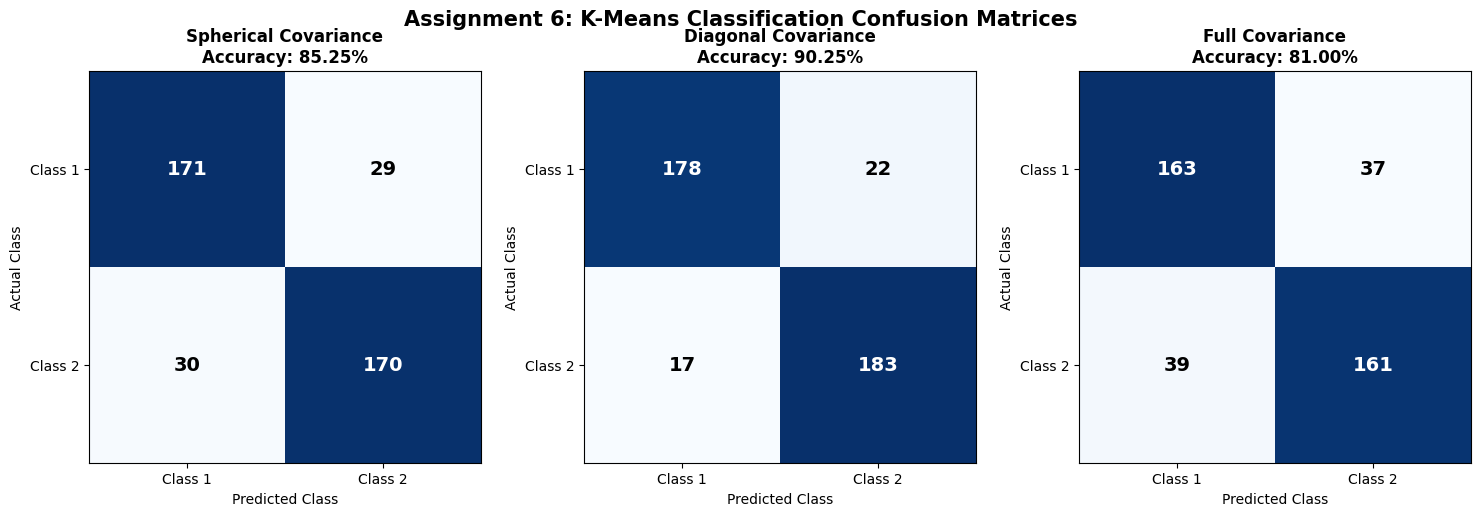

In [10]:

import numpy as np
import matplotlib.pyplot as plt

# Confusion matrices from Assignment 6
cm_spherical = np.array([
    [171, 29],
    [30, 170]
])

cm_diagonal = np.array([
    [178, 22],
    [17, 183]
])

cm_full = np.array([
    [163, 37],
    [39, 161]
])

confusion_matrices = [
    ("Spherical Covariance", cm_spherical),
    ("Diagonal Covariance", cm_diagonal),
    ("Full Covariance", cm_full)
]

# Plot all three confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (title, cm) in zip(axes, confusion_matrices):

    ax.imshow(cm, interpolation="nearest", cmap="Blues")

    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Class 1", "Class 2"])
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Class 1", "Class 2"])

    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

    # Add values with contrasting text colours
    threshold = cm.max() / 2

    for i in range(2):
        for j in range(2):
            ax.text(
                j, i, str(cm[i, j]),
                ha="center",
                va="center",
                color="white" if cm[i, j] > threshold else "black",
                fontsize=14,
                fontweight="bold"
            )

    accuracy = np.trace(cm) / np.sum(cm) * 100
    ax.set_title(
        f"{title}\nAccuracy: {accuracy:.2f}%",
        fontsize=12,
        fontweight="bold"
    )

plt.suptitle(
    "Assignment 6: K-Means Classification Confusion Matrices",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()
